# Problem 1: Network Compression using SVD

In [40]:
import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split, Dataset
from torchvision import datasets, transforms

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"using device {device}")
torch.manual_seed(42)

using device cuda


## Baseline MINST Classifier

I trained a fully connected NN to classify images from the MINST dataset. The model contains 5 hidden layers with 1024 neurons each, ReLU activations, and a final output layer with 10 nuerons corresponding to the digits 0-9

each 28 x 28 image is flattened into a 784 dimensional input vector. The 60,000 training images are divided into 55,000 training and 5,000 validation examples, with an additional 10,000 images held out for testing

the model is trained for 20 epochs using Adam with a learning rate of 0.001 and cross entropy loss. The weights corresponding to the higest validation accuracy are saved for evaluation and compression.

In [6]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_full = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_dataset, val_dataset = random_split(train_full, [55000,5000], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

print(f"Training images {len(train_dataset)}")
print(f"validation images {len(val_dataset)}")
print(f"test images {len(test_dataset)}")


100.0%
100.0%
100.0%
100.0%

Training images 55000
validation images 5000
test images 10000


In [7]:
class MINSTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers=nn.Sequential(
            nn.Linear(784, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.layers(x)

In [8]:
#TEST CELL 

test_model = MINSTClassifier().to(device)
dummy_input = torch.randn(32, 1, 28, 28).to(device)
output = test_model(dummy_input)
print("Output shape:", output.shape)
print("Total parameters:", sum(p.numel() for p in test_model.parameters()))

Output shape: torch.Size([32, 10])
Total parameters: 5012490


In [9]:
def evaluate_model(model, data_loader):
    model.eval()
    correct=0
    total=0
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

In [10]:
torch.manual_seed(42)
model = MINSTClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [11]:
num_epochs = 20
train_losses = []
val_accuracies = []

best_val_acc = 0
best_weights = None

for epoch in range(num_epochs):
    running_loss = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    avg_loss = running_loss / len(train_dataset)
    val_acc = evaluate_model(model, val_loader)
    train_losses.append(avg_loss)
    val_accuracies.append(val_acc)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(model.state_dict())
    print(
        f"Epoch {epoch+1:2d}/{num_epochs} | "
        f"Train Loss: {avg_loss:.4f} | "
        f"Val Accuracy: {val_acc:.2f}%"
    )
model.load_state_dict(best_weights)
torch.save(model.state_dict(), "minst_baseline.pt")
print(f"\nBest validation acc: {best_val_acc:.2f}%")

Epoch  1/20 | Train Loss: 0.2749 | Val Accuracy: 95.94%
Epoch  2/20 | Train Loss: 0.1219 | Val Accuracy: 96.72%
Epoch  3/20 | Train Loss: 0.0917 | Val Accuracy: 97.36%
Epoch  4/20 | Train Loss: 0.0774 | Val Accuracy: 97.26%
Epoch  5/20 | Train Loss: 0.0651 | Val Accuracy: 97.06%
Epoch  6/20 | Train Loss: 0.0523 | Val Accuracy: 97.10%
Epoch  7/20 | Train Loss: 0.0438 | Val Accuracy: 97.18%
Epoch  8/20 | Train Loss: 0.0416 | Val Accuracy: 97.24%
Epoch  9/20 | Train Loss: 0.0376 | Val Accuracy: 96.84%
Epoch 10/20 | Train Loss: 0.0395 | Val Accuracy: 97.70%
Epoch 11/20 | Train Loss: 0.0270 | Val Accuracy: 97.68%
Epoch 12/20 | Train Loss: 0.0292 | Val Accuracy: 97.24%
Epoch 13/20 | Train Loss: 0.0306 | Val Accuracy: 97.74%
Epoch 14/20 | Train Loss: 0.0252 | Val Accuracy: 98.08%
Epoch 15/20 | Train Loss: 0.0276 | Val Accuracy: 97.32%
Epoch 16/20 | Train Loss: 0.0227 | Val Accuracy: 97.70%
Epoch 17/20 | Train Loss: 0.0189 | Val Accuracy: 97.38%
Epoch 18/20 | Train Loss: 0.0197 | Val Accuracy:

In [12]:
test_acc = evaluate_model(model, test_loader)
print(f"baseline test acc: {test_acc:.2f}%")

baseline test acc: 98.17%


## Singular Value Decomp compression 

After training the baseline network, SVD is applied to the weight matrices of the first five fully connected layers. Each weight matrix can be decomposed as:

$$
W = U\Sigma V^T
$$

To compress the network, I retained only the $D$ largest singular values and their corresponding vectors:

$$
\widehat{W}D = U{:,1:D}\Sigma_{1:D,1:D}V^T_{1:D,:}
$$

I evaluated ranks $D={10,20,50,100,200,D_{\text{full}}}$, where full rank preserves all singular values. The final classification layer and all bias terms remain unchanged.

SVD is computed once for each weight matrix, and the approximations are constructed using different values of $D$.

For a layer with $n_{\text{in}}$ inputs and $n_{\text{out}}$ outputs, the number of stored parameters in the factorized representation is:

$$
P_D = D(n_{\text{in}}+n_{\text{out}})+n_{\text{out}}
$$

The final term accounts for the uncompressed bias

In [13]:
linear_layers = [layer for layer in model.layers if isinstance(layer, nn.Linear)]
svd_factors = []

for i, layer in enumerate(linear_layers[:-1]):
    W = layer.weight.detach()
    U, S, Vh = torch.linalg.svd(W, full_matrices=False)
    svd_factors.append((U, S, Vh))
    print(f"Layer {i + 1}: W={tuple(W.shape)}, U={tuple(U.shape)}, S={tuple(S.shape)}, Vh={tuple(Vh.shape)}")

Layer 1: W=(1024, 784), U=(1024, 784), S=(784,), Vh=(784, 784)
Layer 2: W=(1024, 1024), U=(1024, 1024), S=(1024,), Vh=(1024, 1024)
Layer 3: W=(1024, 1024), U=(1024, 1024), S=(1024,), Vh=(1024, 1024)
Layer 4: W=(1024, 1024), U=(1024, 1024), S=(1024,), Vh=(1024, 1024)
Layer 5: W=(1024, 1024), U=(1024, 1024), S=(1024,), Vh=(1024, 1024)


In [14]:
def create_compressed_model(model, svd_factors, rank):
    compressed_model = copy.deepcopy(model)
    compressed_layers = [layer for layer in compressed_model.layers if isinstance(layer, nn.Linear)]
    with torch.no_grad():
        for layer, (U, S, Vh) in zip(compressed_layers[:-1], svd_factors):
            D = min(rank, len(S))
            W_approx = (U[:, :D] * S[:D]) @ Vh[:D, :]
            layer.weight.copy_(W_approx)
    return compressed_model

In [15]:
ranks = [10, 20, 50, 100, 200, 1024]
svd_accuracies = []
for rank in ranks:
    compressed_model = create_compressed_model(model, svd_factors, rank)
    accuracy = evaluate_model(compressed_model, test_loader)
    svd_accuracies.append(accuracy)
    print(f"Rank: {rank:4d} | Test acc: {accuracy:.2f}%")

Rank:   10 | Test acc: 69.58%
Rank:   20 | Test acc: 95.97%
Rank:   50 | Test acc: 98.12%
Rank:  100 | Test acc: 98.18%
Rank:  200 | Test acc: 98.13%
Rank: 1024 | Test acc: 98.17%


In [16]:
baseline_params = sum(p.numel() for p in model.parameters())
def compressed_parameter_count(model, rank):
    layers = [layer for layer in model.layers if isinstance(layer, nn.Linear)]
    total = 0
    for layer in layers[:-1]:
        D = min(rank, min(layer.weight.shape))
        total += D * (layer.in_features + layer.out_features)
        total += layer.out_features
    total += layers[-1].weight.numel()
    total += layers[-1].bias.numel()
    return total

print(f"Baseline parameters: {baseline_params}")
for rank, accuracy in zip(ranks, svd_accuracies):
    if rank == 1024:
        params = baseline_params
    else:
        params = compressed_parameter_count(model, rank)
    reduction = 100*(1-params / baseline_params)
    print(f"Rank {rank:4d} | Accuracy: {accuracy:.2f}% | Parameters: {params:,} | Reduction: {reduction:.2f}%")

Baseline parameters: 5012490
Rank   10 | Accuracy: 69.58% | Parameters: 115,370 | Reduction: 97.70%
Rank   20 | Accuracy: 95.97% | Parameters: 215,370 | Reduction: 95.70%
Rank   50 | Accuracy: 98.12% | Parameters: 515,370 | Reduction: 89.72%
Rank  100 | Accuracy: 98.18% | Parameters: 1,015,370 | Reduction: 79.74%
Rank  200 | Accuracy: 98.13% | Parameters: 2,015,370 | Reduction: 59.79%
Rank 1024 | Accuracy: 98.17% | Parameters: 5,012,490 | Reduction: 0.00%


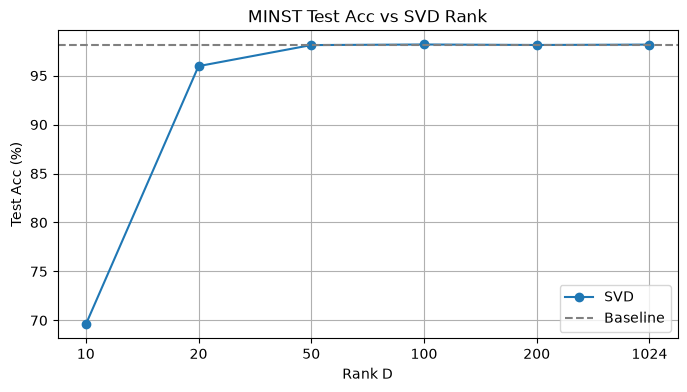

In [17]:
plt.figure(figsize=(8,4))
x_positions = range(len(ranks))
plt.plot(x_positions, svd_accuracies, marker = 'o', label = "SVD")
plt.axhline(
    test_acc,
    linestyle = "--",
    color = "gray",
    label="Baseline"
)
plt.xlabel("Rank D")
plt.ylabel("Test Acc (%)")
plt.title("MINST Test Acc vs SVD Rank")
plt.xticks(x_positions, ranks)
plt.legend()
plt.grid(True)
plt.show()

## Results

The baseline network got 98.17 test accuracy, meeting the assignments target of 98&

As the SVD rank increased, classification accuracy improved. The rank 10 network got only 69.58% accuracy, showing that retaining only 10 singluar value got rid of a lot of important information from the original weight matrices

At rank 20, accuracy improved to 95.97%, while the parameter count decreased from 5,012,490 to 215,370

Rank 50 got 98.12% accuracy with ~90% parameter reduction which comes really close to the original baseline performance. Increasing the rank further did not imporove the model that much

The results show that SVD can reduct the network size a lot while still performing similar to the baseline model. 

# Problem 2: Network Compression Using SVD (Part 2)

## Rank 20 Factorized Network

In problem 1, the rank 20 approximation reducted the networks parameter account a lot, but also decreased classification accuracy. In this problem I attempt to recover that lost accuracy by fine tuning the compressed network

Instead of storing each weight matrix W directly, I represent it as a product of two smaller trainable matrices

$$
W = AB
$$

where $A\in\mathbb{R}^{n_{\text{out}}\times20}$ and $B\in\mathbb{R}^{20\times n_{\text{in}}}$.

The factors are initialized using the SVD components from Problem 1:

$$
A = U_{:,1:20}, \qquad B = \Sigma_{1:20,1:20}V^T_{1:20,:}
$$

This produces the same rank 20 approximation as problem 1, which gives an initial accuracy of 95.97%

The first 5 fully connected layeres are replaced with factorized layers, while the final classification layer remians unchanged.

In [18]:
class FactorizedLinear(nn.Module):
    def __init__(self, in_features, out_features, rank=20):
        super().__init__()
        self.first = nn.Linear(in_features, rank, bias=False)
        self.second = nn.Linear(rank, out_features, bias=True)

    def forward(self, x):
        return self.second(self.first(x))

class FactorizedMINSTClassifier(nn.Module):
    def __init__(self, rank=20):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers=nn.Sequential(
            FactorizedLinear(784, 1024, rank),
            nn.ReLU(),

            FactorizedLinear(1024, 1024, rank),
            nn.ReLU(),

            FactorizedLinear(1024, 1024, rank),
            nn.ReLU(),

            FactorizedLinear(1024, 1024, rank),
            nn.ReLU(),

            FactorizedLinear(1024, 1024, rank),
            nn.ReLU(),

            nn.Linear(1024, 10)
        )

    def forward(self, x):
        return self.layers(self.flatten(x))

In [19]:
rank = 20
factorized_model = FactorizedMINSTClassifier(rank).to(device)

baseline_linear_layers = [layer for layer in model.layers if isinstance(layer, nn.Linear)]
factorized_layers = [layer for layer in factorized_model.layers if isinstance(layer, FactorizedLinear)]

with torch.no_grad():
    for i, layer in enumerate(factorized_layers):
        U, S, Vh = svd_factors[i]
        layer.second.weight.copy_(U[:, :rank])
        layer.first.weight.copy_(S[:rank, None] * Vh[:rank, :])
        layer.second.bias.copy_(baseline_linear_layers[i].bias)

    factorized_model.layers[-1].weight.copy_(baseline_linear_layers[-1].weight)
    factorized_model.layers[-1].bias.copy_(baseline_linear_layers[-1].bias)

In [ ]:
initial_acc = evaluate_model(factorized_model, test_loader)
print(f"Initial factorized acc: {initial_acc:.2f}%")
print("Factorized parameters:", sum(p.numel() for p in factorized_model.parameters()))

Initial factorized acc: 95.97%
Factorized parameters: 215370


In [21]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(factorized_model.parameters(), lr=0.0001)

num_epochs = 20
factorized_train_losses = []
factorized_val_acc = []

best_val_acc = 0
best_weights = None

for epoch in range(num_epochs):
    factorized_model.train()
    running_loss = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = factorized_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    avg_loss = running_loss / len(train_dataset)
    val_acc = evaluate_model(factorized_model, val_loader)
    factorized_train_losses.append(avg_loss)
    factorized_val_acc.append(val_acc)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(factorized_model.state_dict())
    print(f"Epoch {epoch+1:2d} | Train loss: {avg_loss:.4f} | Val Acc: {val_acc:.2f}%")
factorized_model.load_state_dict(best_weights)
torch.save(factorized_model.state_dict(), "minst_factorized_rank20.pt")

Epoch  1 | Train loss: 0.0787 | Val Acc: 97.26%
Epoch  2 | Train loss: 0.0509 | Val Acc: 97.36%
Epoch  3 | Train loss: 0.0400 | Val Acc: 97.50%
Epoch  4 | Train loss: 0.0331 | Val Acc: 97.70%
Epoch  5 | Train loss: 0.0269 | Val Acc: 97.72%
Epoch  6 | Train loss: 0.0227 | Val Acc: 97.58%
Epoch  7 | Train loss: 0.0206 | Val Acc: 97.50%
Epoch  8 | Train loss: 0.0176 | Val Acc: 97.62%
Epoch  9 | Train loss: 0.0154 | Val Acc: 97.90%
Epoch 10 | Train loss: 0.0144 | Val Acc: 97.76%
Epoch 11 | Train loss: 0.0128 | Val Acc: 97.76%
Epoch 12 | Train loss: 0.0107 | Val Acc: 97.80%
Epoch 13 | Train loss: 0.0114 | Val Acc: 97.82%
Epoch 14 | Train loss: 0.0102 | Val Acc: 97.88%
Epoch 15 | Train loss: 0.0073 | Val Acc: 97.92%
Epoch 16 | Train loss: 0.0085 | Val Acc: 97.72%
Epoch 17 | Train loss: 0.0082 | Val Acc: 97.82%
Epoch 18 | Train loss: 0.0086 | Val Acc: 97.62%
Epoch 19 | Train loss: 0.0093 | Val Acc: 97.94%
Epoch 20 | Train loss: 0.0071 | Val Acc: 97.82%


In [22]:
finetuned_acc = evaluate_model(factorized_model, test_loader)

print(f"Original baseline: {test_acc:.2f}%")
print(f"Rank-20 before training: {initial_acc:.2f}%")
print(f"Rank-20 after training: {finetuned_acc:.2f}")
print(f"Best val acc: {best_val_acc:.2f}%")

Original baseline: 98.17%
Rank-20 before training: 95.97%
Rank-20 after training: 97.94
Best val acc: 97.94%


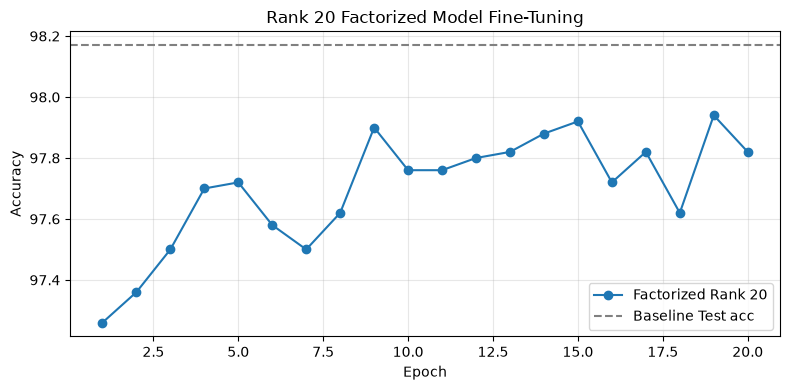

In [23]:
plt.figure(figsize=(8,4))
plt.plot(
    range(1, num_epochs+1),
    factorized_val_acc,
    marker="o",
    label = "Factorized Rank 20"
)
plt.axhline(
    test_acc,
    linestyle = "--",
    color = "gray",
    label="Baseline Test acc"
)
plt.xlabel('Epoch')
plt.ylabel("Accuracy")
plt.title("Rank 20 Factorized Model Fine-Tuning")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Fine tuning results

The factorized network was fine tuned for 20 epochs using Adam with a learning rate of 0.0001, ten times smaller than the baseline LR. The checkpoint with the highest validation accuracy was selected for final evaluation 

Fine tuning improved test accuracy from 95.97% to 97.94%. The netwrok retained 215,370 parameters, cpmpared with 5,012,490 in the original baseline. 

The results show that optimzing the low ranked factors can recover classificaioin performance without increasing the number of parameters

# Problem 3

## SVD Aware Fine tuning

In problem 2, I directly optimzed the two smaller factor matrices. In this problem, I instead retain the original full size weight matrices and apply a 20 rank SVD approximation during each forward pass

For each of the first five layers, the approximated weight matrix is:

$$
\widehat{W}{20}=U{:,1:20}\Sigma_{1:20,1:20}V^T_{1:20,:}
$$

The forward pass uses $\widehat{W}_{20}$ instead of the original weight matrix $W$. However, we still want backpropagation to update the original weights.

To accomplish this, I use a straight-through estimator (STE), which approximates the derivative of the SVD compression function as the identity:

$$
\frac{\partial \widehat{W}}{\partial W}\approx I
$$

In PyTorch, this is implemented using:

W_ste = W + (W_approx - W).detach()

During the forward pass, this expression equals the rank 20 approximation. During backprop, gradients go directly to the original weights without differentiating through SVD

The network is initialized using the baseline weights from problem 1 and fine tuned while accounting for the error introduced by the rank 20 compression

In [24]:
import torch.nn.functional as F

In [25]:
class SVDLinear(nn.Linear):
    def __init__(self, in_features, out_features, rank=20):
        super().__init__(in_features, out_features)
        self.rank = rank

    def forward(self, x):
        with torch.no_grad():
            U, S, Vh = torch.linalg.svd(self.weight, full_matrices=False)
            W_approx = (U[:, :self.rank] * S[:self.rank]) @ Vh[:self.rank, :]
        W_ste = self.weight + (W_approx - self.weight).detach()
        return F.linear(x, W_ste, self.bias)

In [26]:
svd_model = copy.deepcopy(model)
for i, layer in enumerate(svd_model.layers):
    if isinstance(layer, nn.Linear) and i != len(svd_model.layers) - 1:
        new_layer = SVDLinear(layer.in_features, layer.out_features, rank=20).to(device)
        new_layer.load_state_dict(layer.state_dict())
        svd_model.layers[i]=new_layer

In [27]:
initial_svd_acc = evaluate_model(svd_model, test_loader)
print(f"Initial SVD aware acc: {initial_svd_acc:.2f}%")
print("Trainable parameters:", sum(p.numel() for p in svd_model.parameters()))

Initial SVD aware acc: 95.97%
Trainable parameters: 5012490


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(svd_model.parameters(), lr=1e-5)
num_epochs = 5
svd_train_losses = []
svd_val_acc = []
best_val_acc = evaluate_model(svd_model, val_loader)
best_weights = copy.deepcopy(svd_model.state_dict())
print(f"Initial val acc: {best_val_acc:.2f}%")

for epoch in range(num_epochs):
    svd_model.train()
    running_loss = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = svd_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    avg_loss = running_loss / len(train_dataset)
    val_acc = evaluate_model(svd_model, val_loader)
    svd_train_losses.append(avg_loss)
    svd_val_acc.append(val_acc)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(svd_model.state_dict())
    print(f"Epoch {epoch+1:2d} | Train loss: {avg_loss:.4f} | Val Acc: {val_acc:.2f}%")
svd_model.load_state_dict(best_weights)
print(f"\nBest val acc: {best_val_acc:.2f}%")
torch.save(svd_model.state_dict(), "minst_svd_rank20.pt")

Initial val acc: 95.44%
Epoch  1 | Train loss: 0.1209 | Val Acc: 96.20%
Epoch  2 | Train loss: 0.1010 | Val Acc: 96.38%
Epoch  3 | Train loss: 0.0907 | Val Acc: 96.56%
Epoch  4 | Train loss: 0.0831 | Val Acc: 96.70%
Epoch  5 | Train loss: 0.0773 | Val Acc: 96.76%

Best val acc: 96.76%


In [29]:
svd_finetuned_acc = evaluate_model(svd_model, test_loader)

print(f"Original baseline:          {test_acc:.2f}%")
print(f"Rank-20 SVD (Problem 1):    {svd_accuracies[1]:.2f}%")
print(f"Rank-20 factorized (P2):    {finetuned_acc:.2f}%")
print(f"Rank-20 SVD-aware (P3):     {svd_finetuned_acc:.2f}%")

Original baseline:          98.17%
Rank-20 SVD (Problem 1):    95.97%
Rank-20 factorized (P2):    97.94%
Rank-20 SVD-aware (P3):     97.11%


## Results

The SVD aware network was fine tuned for 5 epochs using Adam with a learning rate of 0.00001. The best performing checkpoint was selected using validation accuracy

Before fine tuning, the rank 20 model achieved 95.97% test accuracy. After fine tuning, test accuracy improved to 97.11%

This was slightly below the 97.94% we saw with direct factor fine tuning in problem 2, but it seill shows that incorporating the SVD approximation during training can recover accuracy lost through compression

Unlike problem 2, the network keeps all ~5 million trainable parameters during raining. However, the first five weight matrices are using in rank 20 form during inference can be stored as lower rank factors.

This allows the full size weights to adapt to compression erros while maintaining the possibiblity of a compact inference model 

# Problem 4

## Dataset and speaker pair gen

In this problem, I train a Siamese NN to determine whether two speech recordings belong to the same speaker

The training set has 500 recordings from 50 speakers, while the test set has 200 recordings from 20 speakers. Each speaker has 10 recordings

The audio signals are converted into STFT magnitude spectograms using an FFT size of 1024 and a hop length of 512. This produces sequences of 513 dimensional frequency vectors. The magnitudes are transformed using $\log(1+x)$ to reduce their dynamic range.

For each speaker, I genearte 45 postive paris containing recordings form the same speaker and 45 negative pairs containing recording from different speakers. This produces 4500 balanced training pairs per epoch and 1800 test pairs

Negative training pairs are regenerated each epoch to expose the network to different speaker combinations

In [30]:
import pickle
import librosa

In [31]:
with open("data/trs.pkl", "rb") as f:
    train_audio = pickle.load(f)

with open("data/tes.pkl", "rb") as f:
    test_audio = pickle.load(f)

train_audio = np.asarray(train_audio)
test_audio = np.asarray(test_audio)

print("training shape:", train_audio.shape)
print("testing shape:", test_audio.shape)
print("train dtype", train_audio.dtype)

training shape: (500, 16180)
testing shape: (200, 22631)
train dtype float32


In [32]:
train_speakers = np.repeat(np.arange(50), 10)
test_speakers = np.repeat(np.arange(20), 10)

print("First 25 training speaker labels:")
print(train_speakers[:25])

First 25 training speaker labels:
[0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2]


In [33]:
N_FFT = 1024
HOP_LENGTH = 512

def audio_to_spectogram(audio):
    stft = librosa.stft(audio.astype(np.float32), n_fft=N_FFT, hop_length=HOP_LENGTH)
    return np.abs(stft).T

In [34]:
train_specs = [audio_to_spectogram(audio) for audio in train_audio]
test_specs = [audio_to_spectogram(audio) for audio in test_audio]

print("First training spectrogram:", train_specs[0].shape)
print("First testing spectrogram:", test_specs[0].shape)

First training spectrogram: (32, 513)
First testing spectrogram: (45, 513)


In [35]:
train_specs = [np.log1p(spec).astype(np.float32) for spec in train_specs]
test_specs = [np.log1p(spec).astype(np.float32) for spec in test_specs]
 

In [36]:
from itertools import combinations

In [37]:
def generate_speaker_pairs(speaker_labels, L=45):
    pairs = []
    targets = []
    rng = np.random.default_rng()
    unique_speakers = np.unique(speaker_labels)

    for speaker in unique_speakers:
        speaker_indices = np.where(speaker_labels == speaker)[0]
        other_indicies = np.where(speaker_labels != speaker)[0]
        possible_positive = list(combinations(speaker_indices, 2))
        selected = rng.choice(len(possible_positive), size=L, replace=L > len(possible_positive))
        for idx in selected:
            pairs.append(possible_positive[idx])
            targets.append(1)
        anchor_indices = rng.choice(speaker_indices, size=L, replace=True)
        negative_indices = rng.choice(other_indicies, size=L, replace=True)
        for anchor, negative in zip(anchor_indices, negative_indices):
            pairs.append((anchor, negative))
            targets.append(0)

    return np.array(pairs), np.array(targets, dtype=np.float32)

In [38]:
train_pairs, train_targets = generate_speaker_pairs(train_speakers, L=45)

print("Pair shape:", train_pairs.shape)
print("Target shape:", train_targets.shape)

print("Positive pairs:", int(train_targets.sum()))
print("Negative pairs:", int((train_targets == 0).sum()))

Pair shape: (4500, 2)
Target shape: (4500,)
Positive pairs: 2250
Negative pairs: 2250


In [39]:
for (i, j), target in zip(train_pairs, train_targets):
    assert (train_speakers[i] == train_speakers[j]) == bool(target)

print("All pair labels verified!")

All pair labels verified!


In [41]:
class SpeakerPairDataset(Dataset):
    def __init__(self, spectograms, pairs, targets):
        self.spectograms = [torch.from_numpy(spec) for spec in spectograms]
        self.pairs = pairs
        self.targets = targets

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        i, j = self.pairs[idx]
        return (self.spectograms[i], self.spectograms[j], torch.tensor(self.targets[idx], dtype=torch.float32))
    

In [42]:
train_dataset_pairs = SpeakerPairDataset(train_specs, train_pairs, train_targets)
train_pair_loader = DataLoader(train_dataset_pairs, batch_size=90, shuffle=False)
x1, x2, labels = next(iter(train_pair_loader))
print("Recording A:", x1.shape)
print("Recording B:", x2.shape)
print("Labels:", labels.shape)

Recording A: torch.Size([90, 32, 513])
Recording B: torch.Size([90, 32, 513])
Labels: torch.Size([90])


## Siamese GRU Architecture

The Siamese network uses a shared GRU encoer to convert each recording into a fixed length embedding. 

The encoder has a signle GRU layer with 128 hidden units, followed by a fully connected layer that produced a 64 dimensional embedding. Both reocrdings pass through the same encoder with shared weights

The similarity between the two embeddings is calcuated using their inner product

$$
z = \mathbf{e}_1^T\mathbf{e}_2
$$

The predicted probability that the recordings belong to the same speaker is:

$$
P(\text{same speaker})=\sigma(z)
$$

where $\sigma$ is the sigmoid function.

The network is trained for 30 epochs using Adam with a learning rate of 0.001 and binary cross-entropy loss. BCEWithLogitsLoss applies sigmoid internally during training.

In [43]:
class SpeakerEncoder(nn.Module):
    def __init__(self, input_size = 513, hidden_size = 128, embedding_size = 64):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )
        self.projection = nn.Linear(hidden_size, embedding_size)

    def forward(self, x):
        _, hidden = self.gru(x)
        embedding = self.projection(hidden[-1])
        return embedding

In [44]:
class SiameseSpeakerNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = SpeakerEncoder()

    def forward(self, x1, x2):
        z1 = self.encoder(x1)
        z2 = self.encoder(x2)
        similarity = (z1 * z2).sum(dim=1)
        return similarity
    

In [45]:
speaker_model = SiameseSpeakerNetwork().to(device)
x1 = x1.to(device)
x2 = x2.to(device)
with torch.no_grad():
    logits = speaker_model(x1, x2)
    probabilities = torch.sigmoid(logits)

print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)
print("First 5 probabilities:", probabilities[:5])

Logits shape: torch.Size([90])
Probabilities shape: torch.Size([90])
First 5 probabilities: tensor([0.6058, 0.8278, 0.8537, 0.7980, 0.7973], device='cuda:0')


In [46]:
def evaluate_speaker_model(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x1, x2, labels in loader:
            x1 = x1.to(device)
            x2 = x2.to(device)
            labels = labels.to(device)
            logits = model(x1, x2)
            predictions = (torch.sigmoid(logits) >= 0.5).float()
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

In [47]:
test_pairs, test_targets = generate_speaker_pairs(test_speakers, L=45)
test_pair_dataset = SpeakerPairDataset(test_specs, test_pairs, test_targets)
test_pair_loader = DataLoader(test_pair_dataset, batch_size=90, shuffle=False)

print("Test pairs:", len(test_pair_dataset))
print("Positive:", int(test_targets.sum()))
print("Negative:", int((test_targets == 0).sum()))

Test pairs: 1800
Positive: 900
Negative: 900


In [48]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(speaker_model.parameters(), lr=0.001)
num_epochs = 30
train_losses = []
train_accs = []
test_accs = []
for epoch in range(num_epochs):
    train_pairs, train_targets = generate_speaker_pairs(train_speakers, L=45)
    train_pair_dataset = SpeakerPairDataset(train_specs, train_pairs, train_targets)
    train_pair_loader = DataLoader(train_pair_dataset, batch_size = 90, shuffle=False)
    speaker_model.train()
    running_loss = 0
    for x1, x2, labels in train_pair_loader:
        x1 = x1.to(device)
        x2 = x2.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = speaker_model(x1, x2)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
    avg_loss = running_loss / len(train_pair_dataset)
    train_acc = evaluate_speaker_model(speaker_model, train_pair_loader)
    test_acc = evaluate_speaker_model(speaker_model, test_pair_loader)
    train_losses.append(avg_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)
    print(f"Epoch {epoch+1:2d}/{num_epochs} | Loss: {avg_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

Epoch  1/30 | Loss: 0.6877 | Train Acc: 65.02% | Test Acc: 58.50%
Epoch  2/30 | Loss: 0.6635 | Train Acc: 64.73% | Test Acc: 58.00%
Epoch  3/30 | Loss: 0.6179 | Train Acc: 72.00% | Test Acc: 67.56%
Epoch  4/30 | Loss: 0.6136 | Train Acc: 71.00% | Test Acc: 63.72%
Epoch  5/30 | Loss: 0.5932 | Train Acc: 71.44% | Test Acc: 69.83%
Epoch  6/30 | Loss: 0.5667 | Train Acc: 75.60% | Test Acc: 69.33%
Epoch  7/30 | Loss: 0.5615 | Train Acc: 76.13% | Test Acc: 68.39%
Epoch  8/30 | Loss: 0.5634 | Train Acc: 77.22% | Test Acc: 68.33%
Epoch  9/30 | Loss: 0.5661 | Train Acc: 73.80% | Test Acc: 66.44%
Epoch 10/30 | Loss: 0.5554 | Train Acc: 75.78% | Test Acc: 66.44%
Epoch 11/30 | Loss: 0.5557 | Train Acc: 77.33% | Test Acc: 70.72%
Epoch 12/30 | Loss: 0.5321 | Train Acc: 78.24% | Test Acc: 71.39%
Epoch 13/30 | Loss: 0.5444 | Train Acc: 75.71% | Test Acc: 67.50%
Epoch 14/30 | Loss: 0.5272 | Train Acc: 77.89% | Test Acc: 70.22%
Epoch 15/30 | Loss: 0.5243 | Train Acc: 77.29% | Test Acc: 68.56%
Epoch 16/3

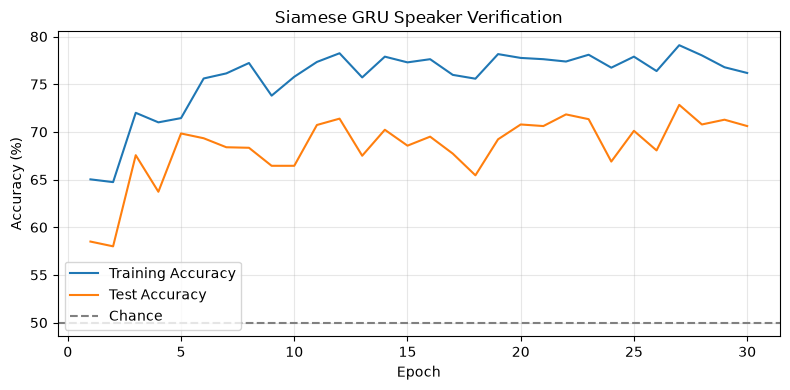

In [49]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 4))

plt.plot(epochs, train_accs, label="Training Accuracy")
plt.plot(epochs, test_accs, label="Test Accuracy")
plt.axhline(50, color="gray", linestyle="--", label="Chance")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Siamese GRU Speaker Verification")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
torch.save(
    speaker_model.state_dict(),
    "speaker_verification_gru.pt"
)

print(f"Final test accuracy: {test_accs[-1]:.2f}%")

Final test accuracy: 70.61%


## Results

After 30 epochs, the Siamese GRU achieved 70.61% test accuracy on recordings from 20 unseen speakers, with a peak accuracy of approximately 72.83% during training.

the final training accuracy was about 76.18%, showing a moderate generalization gap between the training and test speakers.

Overall, the model learned usefule speaker representations and performed a lot better than the 50% chance accuracy of the balanced verification dataset.

# Problem 5

## Dataset and Ideal Binary masks

In this problem, I train a GRU based RNN to remove background noise from speech recordings.

The training dataset contains 1,200 noisy recordings, along with their corresponding clean speech and noise signals. Each recording is converted into an STFT spectrogram with 513 frequency bins and a variable number of time frames.

The noisy STFT magnitudes are used as the network inputs. The clean speech and noise magnitudes are used to construct the ideal binary mask (IBM) targets:

$$
M_{f,t} =
\begin{cases}
1 & \text{if } |S_{f,t}| > |N_{f,t}|\
0 & \text{otherwise}
\end{cases}
$$

A mask value of 1 indicates that speech is stronger than noise at a particular time-frequency location, while 0 indicates that noise is at least as strong as speech.

The noisy magnitudes are transformed using $\log(1+x)$ before being provided to the network. The binary targets remain unchanged.

In [72]:
import soundfile as sf
from pathlib import Path

In [53]:
DATA_DIR = Path("data/timit-homework")
TRAIN_DIR = DATA_DIR / "tr"
VAL_DIR = DATA_DIR / "v"
TEST_DIR = DATA_DIR / "te"

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    files = sorted(folder.glob("*.wav"))
    print(f"\n{folder}: {len(files)} WAV files")
    print([p.name for p in files[:8]])


data/timit-homework/tr: 3600 WAV files
['trn0000.wav', 'trn0001.wav', 'trn0002.wav', 'trn0003.wav', 'trn0004.wav', 'trn0005.wav', 'trn0006.wav', 'trn0007.wav']

data/timit-homework/v: 3600 WAV files
['vn0000.wav', 'vn0001.wav', 'vn0002.wav', 'vn0003.wav', 'vn0004.wav', 'vn0005.wav', 'vn0006.wav', 'vn0007.wav']

data/timit-homework/te: 400 WAV files
['tex0000.wav', 'tex0001.wav', 'tex0002.wav', 'tex0003.wav', 'tex0004.wav', 'tex0005.wav', 'tex0006.wav', 'tex0007.wav']


In [55]:
N_FFT = 1024
HOP_LENGTH = 512

def load_stft(path):
    audio, sr = librosa.load(path, sr=22050)
    stft = librosa.stft(audio, n_fft=N_FFT, hop_length=HOP_LENGTH)
    return stft, audio, sr

def prepare_training_example(noisy_path, clean_path, noise_path):
    X, _, _ = load_stft(noisy_path)
    S, _, _ = load_stft(clean_path)
    N, _, _ = load_stft(noise_path)

    T = min(X.shape[1], S.shape[1], N.shape[1])

    X_mag = np.abs(X[:, :T])
    S_mag = np.abs(S[:, :T])
    N_mag = np.abs(N[:, :T])
    
    mask = (S_mag > N_mag).astype(np.float32)
    features = np.log1p(X_mag).T.astype(np.float32)
    targets = mask.T
    
    return features, targets 



In [57]:
train_features = []
train_masks = []

for i in range(1200):
    x, mask = prepare_training_example(
        TRAIN_DIR / f"trx{i:04d}.wav",
        TRAIN_DIR / f"trs{i:04d}.wav",
        TRAIN_DIR / f"trn{i:04d}.wav"
    )
    train_features.append(x)
    train_masks.append(mask)

print("Number of examples:", len(train_features))
print("First input shape:", train_features[0].shape)
print("First target shape:", train_masks[0].shape)
print("Unique target values:", np.unique(train_masks[0]))

Number of examples: 1200
First input shape: (90, 513)
First target shape: (90, 513)
Unique target values: [0. 1.]


## GRU Architecture and Training

The denoising network consists of two GRU layers with 128 hidden units each and a dropout rate of 0.1. A fully connected output layer maps the GRU hidden states to 513 mask predictions per time frame.

The model processes the frequency spectra as a sequence, allowing it to learn temporal relationships in speech that a fully connected network cannot directly capture.

To handle variable-length recordings during training, each recording is divided into randomly sampled sequences of 64 time frames. Mini-batches contain 32 sequences.

The network is trained for 15 epochs using Adam with a learning rate of 0.001 and binary cross-entropy loss.

During inference, sigmoid converts the network outputs into mask values between 0 and 1. These predicted masks are multiplied elementwise by the original complex-valued noisy STFT:

$$
\widehat{S}{f,t}=\widehat{M}{f,t}X_{f,t}
$$

An inverse STFT is then applied to reconstruct the denoised waveform.

Although the training targets are binary, I use the continuous sigmoid probabilities as soft masks during reconstruction.

In [58]:
class GRUDenoiser(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(
            input_size=513,
            hidden_size=128,
            num_layers=2,
            dropout=0.1,
            batch_first=True
        )
        self.output = nn.Linear(128, 513)

    def forward(self, x):
        hidden_states, _ = self.gru(x)
        logits = self.output(hidden_states)
        return logits

In [61]:
class SpeechChunkDataset(Dataset):
    def __init__(self, features, masks, chunk_length = 64, chunks_per_file = 8):
        self.features = features
        self.masks = masks
        self.chunk_length = chunk_length
        self.chunks_per_file = chunks_per_file
    
    def __len__(self):
        return len(self.features) * self.chunks_per_file
    
    def __getitem__(self, index):
        file_idx = index // self.chunks_per_file
        x = self.features[file_idx]
        y = self.masks[file_idx]

        T = len(x)

        if T >= self.chunk_length:
            start = np.random.randint(0, T - self.chunk_length + 1)
            x = x[start:start + self.chunk_length]
            y = y[start:start + self.chunk_length]
        else:
            pad = self.chunk_length - T
            x = np.pad(x, ((0, pad), (0, 0)))
            y = np.pad (y, ((0, pad), (0, 0)))
        return torch.from_numpy(x), torch.from_numpy(y)

In [62]:
train_dataset = SpeechChunkDataset(train_features, train_masks)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

x, y = next(iter(train_loader))
print("Input batch:", x.shape)
print("Target batch:", y.shape)

Input batch: torch.Size([32, 64, 513])
Target batch: torch.Size([32, 64, 513])


In [64]:
torch.manual_seed(42)
denoiser = GRUDenoiser().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(denoiser.parameters(), lr = 0.001)
num_epochs = 15
train_losses = []

for epoch in range(num_epochs):
    denoiser.train()
    running_loss = 0
    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)
        optimizer.zero_grad()
        logits = denoiser(x)
        loss = criterion(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm(denoiser.parameters(), 5.0)
        optimizer.step()
        running_loss += loss.item()
    avg_loss = running_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch {epoch+1:2d}/{num_epochs} | Train loss: {avg_loss:.4f}")

torch.save(denoiser.state_dict(), "gru_denoiser.pt")

/tmp/ipykernel_6306/1016807122.py:18: FutureWarning: `torch.nn.utils.clip_grad_norm` is now deprecated in favor of `torch.nn.utils.clip_grad_norm_`.
  torch.nn.utils.clip_grad_norm(denoiser.parameters(), 5.0)


Epoch  1/15 | Train loss: 0.5576
Epoch  2/15 | Train loss: 0.4805
Epoch  3/15 | Train loss: 0.4578
Epoch  4/15 | Train loss: 0.4424
Epoch  5/15 | Train loss: 0.4323
Epoch  6/15 | Train loss: 0.4248
Epoch  7/15 | Train loss: 0.4166
Epoch  8/15 | Train loss: 0.4104
Epoch  9/15 | Train loss: 0.4049
Epoch 10/15 | Train loss: 0.3997
Epoch 11/15 | Train loss: 0.3959
Epoch 12/15 | Train loss: 0.3916
Epoch 13/15 | Train loss: 0.3893
Epoch 14/15 | Train loss: 0.3863
Epoch 15/15 | Train loss: 0.3840


In [68]:
def denoise_audio(model, noisy_audio):
    model.eval()
    X = librosa.stft(noisy_audio, n_fft=N_FFT, hop_length=HOP_LENGTH)
    features = np.log1p(np.abs(X)).T.astype(np.float32)
    x = torch.from_numpy(features).unsqueeze(0).to(device)
    
    with torch.no_grad():
        logits = model(x)
        mask = torch.sigmoid(logits)[0].cpu().numpy().T

    estimated_stft = mask * X
    reconstructed = librosa.istft(estimated_stft, hop_length=HOP_LENGTH, length=len(noisy_audio))
    return reconstructed

In [66]:
def calculate_snr(clean, predicted):
    length = min(len(clean), len(predicted))
    clean = clean[:length]
    predicted = predicted[:length]
    signal_power = np.sum(clean ** 2)
    error_power = np.sum((clean-predicted) ** 2)
    return 10 * np.log10(
        (signal_power + 1e-10) / (error_power + 1e-10)
    )

In [69]:
noisy_snrs = []
denoised_snrs = []

for i in range(100):
    noisy, sr = librosa.load(VAL_DIR / f"vx{i:04d}.wav", sr = 22050)
    clean, _ = librosa.load(VAL_DIR / f"vs{i:04d}.wav", sr = 22050)
    denoised = denoise_audio(denoiser, noisy)
    noisy_snrs.append(calculate_snr(clean, noisy))
    denoised_snrs.append(calculate_snr(clean, denoised))

print(f"Average noisy SNR:    {np.mean(noisy_snrs):.2f} dB")
print(f"Average denoised SNR: {np.mean(denoised_snrs):.2f} dB")
print(f"Improvement:          {np.mean(denoised_snrs) - np.mean(noisy_snrs):+.2f} dB")

Average noisy SNR:    0.04 dB
Average denoised SNR: 10.06 dB
Improvement:          +10.02 dB


In [70]:
from IPython.display import Audio, display

i = 0
noisy, sr = librosa.load(VAL_DIR / f"vx{i:04d}.wav", sr=22050)
clean, _ = librosa.load(VAL_DIR / f"vs{i:04d}.wav", sr=22050)
denoised = denoise_audio(denoiser, noisy)

print("Original noisy speech:")
display(Audio(noisy, rate=sr))

print("Denoised speech:")
display(Audio(denoised, rate=sr))

print("Original clean speech:")
display(Audio(clean, rate=sr))

Original noisy speech:


Denoised speech:


Original clean speech:


## Validation results and Test Reconstruction

The GRU training loss decreased steadily from 0.5576 to 0.3840 over 15 epochs, showing that the model learned to predict the ideal binary masks

Performance was evaluted on the first 100 validation recordings using singal to noise ratio
$$
\mathrm{SNR}=10\log_{10}
\left(
\frac{\sum_t s(t)^2}
{\sum_t(s(t)-\widehat{s}(t))^2}
\right)
$$

The average noisy SNR was 0.04 dB, while the reconstructed speech got 10.06 dB.

These results show that the GRU reduced a lot of background nosie. The trinaed model was applied to all 400 test recordings. The recovered speech ignals were saved as WAV files and packaged into denoised_test_zip for submssion. 

In [73]:
OUTPUT_DIR = Path("outputs/denoised_test")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for i in range(400):
    test_path = TEST_DIR / f"tex{i:04d}.wav"

    noisy, sr = librosa.load(test_path, sr=22050)
    denoised = denoise_audio(denoiser, noisy)

    output_path = OUTPUT_DIR / f"tes{i:04d}.wav"
    sf.write(output_path, denoised, sr)

print(f"Saved {len(list(OUTPUT_DIR.glob('*.wav')))} denoised recordings")

Saved 400 denoised recordings


In [74]:
import zipfile

In [75]:
with zipfile.ZipFile("denoised_test.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(OUTPUT_DIR.glob("*.wav")):
        zf.write(path, arcname=path.name)

print("Created denoised_test.zip")

Created denoised_test.zip
